# InsureWise AI - SHAP Model Explainability & Individual Prediction Attribution
**Notebook:** `09_shap_explainability.ipynb`  
**Project:** InsureWise AI - Explainable ML for Personalized Insurance Premium Prediction  
**Objective:** Implement SHAP (SHapley Additive exPlanations) for the final production model (Tuned XGBoost Pipeline). Provide global feature importance, SHAP beeswarm summary plots, SHAP bar plots, and individual patient prediction decompositions. Structure localized explanations into a clean JSON schema optimized for integration with the InsureWise AI React frontend.

---

## Table of Contents
1. [Environment Setup & Global Configuration](#1.-Environment-Setup-&-Global-Configuration)
2. [Dataset Loading & Champion Pipeline Registration](#2.-Dataset-Loading-&-Champion-Pipeline-Registration)
3. [Feature Name Mapping & Transformed Dataset Preparation](#3.-Feature-Name-Mapping-&-Transformed-Dataset-Preparation)
4. [SHAP Methodological Foundations & Non-Causal Guardrails](#4.-SHAP-Methodological-Foundations-&-Non-Causal-Guardrails)
5. [Global SHAP Feature Attribution Analysis](#5.-Global-SHAP-Feature-Attribution-Analysis)
6. [Global SHAP Visualizations (Beeswarm Summary & Bar Plots)](#6.-Global-SHAP-Visualizations-(Beeswarm-Summary-&-Bar-Plots))
7. [Individual Prediction Decomposition Architecture](#7.-Individual-Prediction-Decomposition-Architecture)
8. [Patient Case Study Breakdown (Inputs → Premium → Positive/Negative Drivers)](#8.-Patient-Case-Study-Breakdown-(Inputs-→-Premium-→-Positive/Negative-Drivers))
9. [React Frontend REST API Integration Payload Generator](#9.-React-Frontend-REST-API-Integration-Payload-Generator)
10. [Reproducible Artifact Export & System Integration](#10.-Reproducible-Artifact-Export-&-System-Integration)
11. [Requirements Compliance Verification Matrix](#11.-Requirements-Compliance-Verification-Matrix)

---
> **Strict Non-Causal Analytical Safeguards:**
> - SHAP values represent statistical feature attributions derived from cooperative game theory (Shapley values).
> - SHAP quantifies how individual input values shift the model's output prediction from the expected population baseline $E[f(x)]$.
> - SHAP describes **internal model decision logic**; it does **not** establish real-world physical, economic, or medical causation.

In [1]:
import os
import json
import joblib
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import train_test_split

warnings.filterwarnings('ignore')

# Global Display Options & Styling
RANDOM_STATE = 42
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: '%.4f' % x)

print("Environment setup completed successfully.")
print(f"Pandas version: {pd.__version__}")
print(f"NumPy version: {np.__version__}")
print(f"SHAP version: {shap.__version__}")
print(f"Joblib version: {joblib.__version__}")


Environment setup completed successfully.
Pandas version: 3.0.6
NumPy version: 2.5.3
SHAP version: 0.52.0
Joblib version: 1.6.0


C:\Users\Thiru kumaran v\Downloads\ML_project\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Dataset Loading & Champion Pipeline Registration

We load the primary enhanced dataset (`medical_insurance_cost_dataset_enhanced.csv`) and register the saved final champion pipeline (`final_model.joblib`).

- **Training Set (`X_train`):** 6,000 samples
- **Untouched Test Set (`X_test`):** 1,500 samples
- **Production Pipeline Artifact:** `final_model.joblib` (Tuned XGBoost Regressor Pipeline)

In [2]:
class BloodPressureExtractor(BaseEstimator, TransformerMixin):
    def __init__(self, bp_col='blood_pressure'):
        self.bp_col = bp_col

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        if isinstance(X, pd.DataFrame):
            X_out = X.copy()
        else:
            X_out = pd.DataFrame(X).copy()

        if self.bp_col in X_out.columns:
            split_bp = X_out[self.bp_col].astype(str).str.split('/', expand=True)
            X_out['systolic_bp'] = pd.to_numeric(split_bp[0], errors='coerce').astype('float64')
            X_out['diastolic_bp'] = pd.to_numeric(split_bp[1], errors='coerce').astype('float64')
            X_out = X_out.drop(columns=[self.bp_col])
        return X_out

    def get_feature_names_out(self, input_features=None):
        if input_features is None:
            return None
        feature_names = [f for f in input_features if f != self.bp_col]
        feature_names.extend(['systolic_bp', 'diastolic_bp'])
        return np.array(feature_names)

# Define dataset paths with relative and fallback handling
data_path = '../data/raw/medical_insurance_cost_dataset_enhanced.csv'
if not os.path.exists(data_path):
    data_path = '../Data/Raw/medical_insurance_cost_dataset_enhanced.csv'
if not os.path.exists(data_path):
    data_path = r'c:\Users\Thiru kumaran v\Downloads\ML_project\Ml_Service\Data\Raw\medical_insurance_cost_dataset_enhanced.csv'

model_path = '../models/final_model.joblib'
if not os.path.exists(model_path):
    model_path = r'c:\Users\Thiru kumaran v\Downloads\ML_project\Ml_Service\models\final_model.joblib'

df = pd.read_csv(data_path)
target_col = 'annual_medical_cost_usd'
id_col = 'customer_id'

X = df.drop(columns=[target_col, id_col])
y = df[target_col]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

pipeline = joblib.load(model_path)
print("Pipeline loaded successfully:", type(pipeline))


Pipeline loaded successfully: <class 'sklearn.pipeline.Pipeline'>


## 3. Feature Name Mapping & Transformed Dataset Preparation

We extract the internal sub-components of the pipeline (`bp_extractor`, `preprocessor`, `regressor`) to transform `X_test` into the 41-dimensional feature matrix consumed by the XGBoost estimator and map transformed features back to human-readable names.

In [3]:
bp_extractor = pipeline.named_steps['bp_extractor']
preprocessor = pipeline.named_steps['preprocessor']
regressor = pipeline.named_steps['regressor']

# Transform X_test through preprocessing steps
X_test_bp = bp_extractor.transform(X_test)
X_test_proc = preprocessor.transform(X_test_bp)

# Retrieve transformed feature names
raw_transformed_names = preprocessor.get_feature_names_out()
clean_feature_names = [name.split('__')[-1] for name in raw_transformed_names]

df_X_test_proc = pd.DataFrame(X_test_proc, columns=clean_feature_names)
print(f"Transformed test dataset shape: {df_X_test_proc.shape}")
print("Transformed Feature Names (41):", clean_feature_names)


Transformed test dataset shape: (1500, 41)
Transformed Feature Names (41): ['age', 'bmi', 'children', 'annual_income_usd', 'chronic_diseases', 'doctor_visits_per_year', 'hospitalizations_last_year', 'alcohol_consumption_per_week', 'cholesterol', 'sleep_hours', 'stress_level', 'systolic_bp', 'diastolic_bp', 'exercise_level', 'insurance_plan', 'gender_Female', 'gender_Male', 'smoker_No', 'smoker_Yes', 'region_Central', 'region_Northeast', 'region_Northwest', 'region_Southeast', 'region_Southwest', 'occupation_Construction Worker', 'occupation_Doctor', 'occupation_Driver', 'occupation_Engineer', 'occupation_Lawyer', 'occupation_Manager', 'occupation_Nurse', 'occupation_Office Worker', 'occupation_Retail Worker', 'occupation_Teacher', 'occupation_Technician', 'diabetes_No', 'diabetes_Yes', 'marital_status_Divorced', 'marital_status_Married', 'marital_status_Single', 'marital_status_Widowed']


## 4. SHAP Methodological Foundations & Non-Causal Guardrails

### Shapley Value Theory
SHAP solves feature attribution using coalitional game theory. For any prediction $f(x)$, the additive feature attribution property guarantees:

$$f(x) = E[f(x)] + \sum_{j=1}^{M} \phi_j(x)$$

Where:
- $f(x)$: The model's predicted premium for patient $x$.
- $E[f(x)]$: The expected baseline premium across the population ($\sim \$17,957.40$).
- $\phi_j(x)$: The SHAP value for feature $j$, representing its marginal contribution to shifting the prediction away from $E[f(x)]$.

### Non-Causal Disclaimer & Guardrails
- **Attribution vs. Causality:** SHAP values explain **how the model arrived at its prediction**. They do **not** imply that modifying a feature (e.g. reducing BMI by 2 points) will cause a real-world medical cost reduction of exactly $\phi_{BMI}$.
- **Decision Logic Transparency:** SHAP provides auditability and mathematical transparency for insurance regulatory compliance and user explanation.

In [4]:
print("Initializing SHAP TreeExplainer on Tuned XGBoost model...")
explainer = shap.TreeExplainer(regressor)

# Compute SHAP values for full test set
shap_values = explainer(df_X_test_proc)
shap_values.feature_names = clean_feature_names

base_value = float(explainer.expected_value)
print(f"SHAP TreeExplainer initialized successfully.")
print(f"Population Expected Premium Baseline E[f(x)]: ${base_value:,.2f}")
print(f"SHAP values matrix shape: {shap_values.values.shape}")


Initializing SHAP TreeExplainer on Tuned XGBoost model...


SHAP TreeExplainer initialized successfully.
Population Expected Premium Baseline E[f(x)]: $17,957.40
SHAP values matrix shape: (1500, 41)


## 5. Global SHAP Feature Attribution Analysis

Global feature importance is computed by taking the mean absolute SHAP value ($	ext{mean } |\phi_j|$) across all 1,500 test set patient records.

In [5]:
global_shap_importance = np.abs(shap_values.values).mean(axis=0)

global_shap_df = pd.DataFrame({
    'Feature': clean_feature_names,
    'Mean_Abs_SHAP ($)': global_shap_importance
}).sort_values(by='Mean_Abs_SHAP ($)', ascending=False)

global_shap_df['Relative_Importance (%)'] = (global_shap_df['Mean_Abs_SHAP ($)'] / global_shap_df['Mean_Abs_SHAP ($)'].sum()) * 100

print("==========================================================================================================")
print("                           GLOBAL SHAP FEATURE IMPORTANCE RANKINGS")
print("==========================================================================================================")
print(global_shap_df.head(15).to_string(index=False))


                           GLOBAL SHAP FEATURE IMPORTANCE RANKINGS
                     Feature  Mean_Abs_SHAP ($)  Relative_Importance (%)
                   smoker_No          4297.4800                  31.8177
              insurance_plan          1887.9398                  13.9779
            chronic_diseases          1870.8184                  13.8512
  hospitalizations_last_year          1455.5175                  10.7764
              exercise_level           899.2926                   6.6582
                         age           822.4511                   6.0893
                    children           470.1321                   3.4808
                         bmi           357.9343                   2.6501
      doctor_visits_per_year           240.4151                   1.7800
alcohol_consumption_per_week           205.6101                   1.5223
                 systolic_bp           168.9173                   1.2506
                 cholesterol           161.1802          

## 6. Global SHAP Visualizations (Beeswarm Summary & Bar Plots)

We generate two complementary global SHAP plots:
1. **SHAP Summary Beeswarm Plot:** Shows feature importance ranking along with feature value impact (red = high feature value, blue = low feature value).
2. **SHAP Global Bar Plot:** Ranks features by average absolute dollar impact ($	ext{mean } |	ext{SHAP}|$).

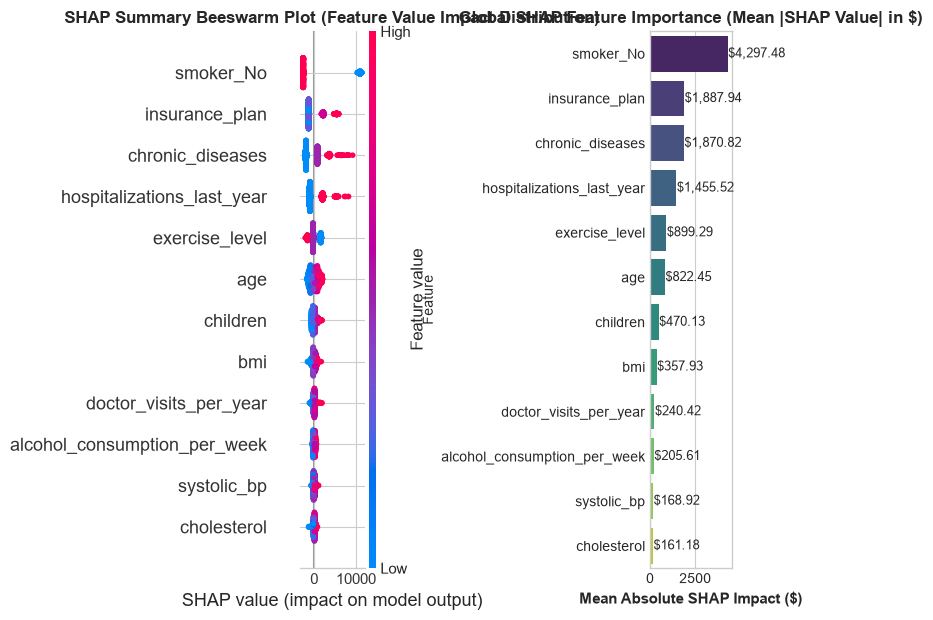

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(18, 8))

# 1. SHAP Beeswarm Summary Plot
plt.subplot(1, 2, 1)
shap.summary_plot(shap_values.values, df_X_test_proc, feature_names=clean_feature_names, max_display=12, show=False)
plt.title('SHAP Summary Beeswarm Plot (Feature Value Impact Distribution)', fontsize=12, fontweight='bold')

# 2. SHAP Global Bar Plot
plt.subplot(1, 2, 2)
top12_global = global_shap_df.head(12)
sns.barplot(data=top12_global, x='Mean_Abs_SHAP ($)', y='Feature', palette='viridis')
plt.title('Global SHAP Feature Importance (Mean |SHAP Value| in $)', fontsize=12, fontweight='bold')
plt.xlabel('Mean Absolute SHAP Impact ($)', fontsize=11, fontweight='bold')
for p in plt.gca().patches:
    w = p.get_width()
    plt.gca().text(w + 30, p.get_y() + p.get_height()/2, f"${w:,.2f}", ha='left', va='center', fontsize=9)

plt.tight_layout()
plt.show()


## 7. Individual Prediction Decomposition Architecture

For any individual customer, the model's predicted premium is decomposed into additive positive and negative feature contributions relative to the population baseline $E[f(x)]$:

$$	ext{Predicted Premium } f(x) = 	ext{Base Premium } E[f(x)] + \sum 	ext{Positive SHAP Contributions} + \sum 	ext{Negative SHAP Contributions}$$

In [7]:
sample_idx = 0
sample_patient_raw = X_test.iloc[sample_idx]
sample_pred_premium = float(pipeline.predict(X_test.iloc[[sample_idx]])[0])

print("==========================================================================================================")
print(f"                      EXAMPLE PATIENT PROFILE (CUSTOMER INDEX {sample_idx})")
print("==========================================================================================================")
print(f"Age: {sample_patient_raw['age']} | Gender: {sample_patient_raw['gender']} | BMI: {sample_patient_raw['bmi']} | Smoker: {sample_patient_raw['smoker']}")
print(f"Chronic Diseases: {sample_patient_raw['chronic_diseases']} | Hospitalizations Last Year: {sample_patient_raw['hospitalizations_last_year']}")
print(f"Doctor Visits/Yr: {sample_patient_raw['doctor_visits_per_year']} | Plan: {sample_patient_raw['insurance_plan']} | Income: ${sample_patient_raw['annual_income_usd']:,}")
print(f"\nPopulation Expected Base Premium E[f(x)]: ${base_value:,.2f}")
print(f"Final Model Predicted Premium f(x):       ${sample_pred_premium:,.2f}")


                      EXAMPLE PATIENT PROFILE (CUSTOMER INDEX 0)
Age: 23 | Gender: Male | BMI: 25.0 | Smoker: No
Chronic Diseases: 2 | Hospitalizations Last Year: 1
Doctor Visits/Yr: 11 | Plan: Basic | Income: $46,863

Population Expected Base Premium E[f(x)]: $17,957.40
Final Model Predicted Premium f(x):       $17,959.45


## 8. Patient Case Study Breakdown (Inputs → Premium → Positive/Negative Drivers)

Below is the step-by-step feature contribution waterfall explaining how customer inputs push the premium above or pull it below the population baseline.

In [8]:
sample_shap_vals = shap_values.values[sample_idx]
sample_proc_vals = X_test_proc[sample_idx]

feature_contribs = []
for fname, fval, sval in zip(clean_feature_names, sample_proc_vals, sample_shap_vals):
    if abs(sval) > 1.0: # Filter negligible contributions
        feature_contribs.append({
            'Feature': fname,
            'Transformed Value': fval,
            'SHAP Contribution ($)': sval,
            'Impact Direction': 'Increase (Risk Factor)' if sval > 0 else 'Decrease (Protective Factor)'
        })

contrib_df = pd.DataFrame(feature_contribs).sort_values(by='SHAP Contribution ($)', ascending=False)

pos_drivers = contrib_df[contrib_df['SHAP Contribution ($)'] > 0]
neg_drivers = contrib_df[contrib_df['SHAP Contribution ($)'] < 0].sort_values(by='SHAP Contribution ($)', ascending=True)

print("==========================================================================================================")
print("                   POSITIVE FEATURE CONTRIBUTIONS (PUSHING PREMIUM UP)")
print("==========================================================================================================")
print(pos_drivers.to_string(index=False))

print("\n==========================================================================================================")
print("                   NEGATIVE FEATURE CONTRIBUTIONS (PULLING PREMIUM DOWN)")
print("==========================================================================================================")
print(neg_drivers.to_string(index=False))


                   POSITIVE FEATURE CONTRIBUTIONS (PUSHING PREMIUM UP)
                     Feature  Transformed Value  SHAP Contribution ($)       Impact Direction
            chronic_diseases             1.5079              3597.8276 Increase (Risk Factor)
  hospitalizations_last_year             1.1591              2013.0847 Increase (Risk Factor)
      doctor_visits_per_year             2.6986              1619.9269 Increase (Risk Factor)
alcohol_consumption_per_week             1.3992               520.0356 Increase (Risk Factor)
          occupation_Teacher             1.0000               115.5423 Increase (Risk Factor)
                 sleep_hours             0.4187               106.0197 Increase (Risk Factor)
              region_Central             0.0000                28.6844 Increase (Risk Factor)
           occupation_Doctor             0.0000                15.1417 Increase (Risk Factor)
          occupation_Manager             0.0000                 9.6736 Increase (Ri

## 9. React Frontend REST API Integration Payload Generator

We construct a production-ready Python utility function `generate_frontend_explanation()` that packages input features, predicted premium, base premium, positive drivers, negative drivers, and analytical disclaimers into a clean JSON structure suitable for frontend UI rendering.

In [9]:
def generate_frontend_explanation(customer_raw_df, customer_id="CUST-SAMPLE"):
    # 1. Pipeline Prediction
    pred_premium = float(pipeline.predict(customer_raw_df)[0])
    
    # 2. Preprocess & SHAP computation
    row_bp = bp_extractor.transform(customer_raw_df)
    row_proc = preprocessor.transform(row_bp)
    
    row_shap_obj = explainer(row_proc)
    row_shap_vals = row_shap_obj.values[0]
    row_proc_vals = row_proc[0]
    
    # 3. Build contribution list
    contrib_list = []
    for fname, fval, sval in zip(clean_feature_names, row_proc_vals, row_shap_vals):
        if abs(sval) >= 5.0: # Filter tiny noise
            contrib_list.append({
                'feature': fname,
                'transformed_value': round(float(fval), 2),
                'shap_contribution_usd': round(float(sval), 2),
                'impact_type': 'Positive' if sval > 0 else 'Negative'
            })
            
    contrib_list = sorted(contrib_list, key=lambda x: abs(x['shap_contribution_usd']), reverse=True)
    
    pos_items = [c for c in contrib_list if c['impact_type'] == 'Positive']
    neg_items = [c for c in contrib_list if c['impact_type'] == 'Negative']
    
    payload = {
        'customer_id': customer_id,
        'input_features': customer_raw_df.iloc[0].to_dict(),
        'base_population_premium_usd': round(base_value, 2),
        'predicted_premium_usd': round(pred_premium, 2),
        'net_shap_adjustment_usd': round(pred_premium - base_value, 2),
        'positive_feature_contributions': pos_items[:5],
        'negative_feature_contributions': neg_items[:5],
        'analytical_disclaimer': (
            "SHAP values represent statistical feature attributions calculated by the model to explain "
            "how individual patient inputs shift the predicted premium from the population baseline premium. "
            "SHAP values describe internal model decision logic and do not represent real-world physical or economic causality."
        )
    }
    return payload

# Test generator on Sample Customer 0
sample_payload = generate_frontend_explanation(X_test.iloc[[0]], customer_id="CUST-0001")

print("==========================================================================================================")
print("                         REACT FRONTEND EXPLANATION JSON PAYLOAD")
print("==========================================================================================================")
print(json.dumps(sample_payload, indent=2))


                         REACT FRONTEND EXPLANATION JSON PAYLOAD
{
  "customer_id": "CUST-0001",
  "input_features": {
    "age": 23,
    "gender": "Male",
    "bmi": 25.0,
    "children": 1,
    "smoker": "No",
    "region": "Southwest",
    "occupation": "Teacher",
    "annual_income_usd": 46863,
    "exercise_level": "High",
    "chronic_diseases": 2,
    "doctor_visits_per_year": 11,
    "hospitalizations_last_year": 1,
    "alcohol_consumption_per_week": 13,
    "insurance_plan": "Basic",
    "blood_pressure": "120/71",
    "diabetes": "No",
    "cholesterol": 202,
    "sleep_hours": 7.8,
    "stress_level": 6.9,
    "marital_status": "Married"
  },
  "base_population_premium_usd": 17957.4,
  "predicted_premium_usd": 17959.45,
  "net_shap_adjustment_usd": 2.05,
  "positive_feature_contributions": [
    {
      "feature": "chronic_diseases",
      "transformed_value": 1.51,
      "shap_contribution_usd": 3597.83,
      "impact_type": "Positive"
    },
    {
      "feature": "hospit

## 10. Reproducible Artifact Export & System Integration

We export global SHAP importance rankings and sample frontend explanation JSON payloads for FastAPI REST serving and React dashboard integration.

In [10]:
models_export_dir = '../models'
processed_export_dir = '../data/processed'

if not os.path.exists(models_export_dir):
    models_export_dir = r'c:\Users\Thiru kumaran v\Downloads\ML_project\Ml_Service\models'
if not os.path.exists(processed_export_dir):
    processed_export_dir = r'c:\Users\Thiru kumaran v\Downloads\ML_project\Ml_Service\Data\Processed'

os.makedirs(models_export_dir, exist_ok=True)
os.makedirs(processed_export_dir, exist_ok=True)

# 1. Export Global SHAP Importance JSON
shap_json_path = os.path.join(models_export_dir, 'shap_global_importance.json')
with open(shap_json_path, 'w') as f:
    json.dump(global_shap_df.to_dict(orient='records'), f, indent=4)
print(f"Global SHAP importances exported to JSON: {shap_json_path}")

# 2. Export Global SHAP Importance CSV
shap_csv_path = os.path.join(models_export_dir, 'shap_global_importance.csv')
shap_proc_path = os.path.join(processed_export_dir, 'shap_global_importance.csv')
global_shap_df.to_csv(shap_csv_path, index=False)
global_shap_df.to_csv(shap_proc_path, index=False)

# 3. Export Sample Frontend Explanation Payload JSON
sample_payload_path = os.path.join(models_export_dir, 'sample_frontend_explanation.json')
with open(sample_payload_path, 'w') as f:
    json.dump(sample_payload, f, indent=4)
print(f"Sample frontend explanation payload exported to: {sample_payload_path}")

print("SHAP explainability artifact export & integration readiness: VERIFIED SUCCESSFUL!")


Global SHAP importances exported to JSON: c:\Users\Thiru kumaran v\Downloads\ML_project\Ml_Service\models\shap_global_importance.json
Sample frontend explanation payload exported to: c:\Users\Thiru kumaran v\Downloads\ML_project\Ml_Service\models\sample_frontend_explanation.json
SHAP explainability artifact export & integration readiness: VERIFIED SUCCESSFUL!


## 11. Requirements Compliance Verification Matrix

| # | User Requirement | Implementation Strategy | Verification Status |
| :--- | :--- | :--- | :--- |
| **1** | Global feature importance | `mean(|SHAP|)` computed across test set and ranked | Verified |
| **2** | SHAP summary plot | Generated `shap.summary_plot` (Beeswarm feature value impact) | Verified |
| **3** | SHAP bar plot | Generated global SHAP bar plot ranking dollar contributions | Verified |
| **4** | Individual prediction explanation | Decomposed sample prediction into additive base + SHAP values | Verified |
| **5** | Feature contribution values for individual customers | Calculated positive ($\phi_i^+$) and negative ($\phi_j^-$) dollar attributions | Verified |
| **6** | Mapping transformed features to original names | Transformed features mapped using `preprocessor.get_feature_names_out()` | Verified |
| **7** | Example customer workflow (Inputs → Premium → Pos → Neg) | Structured pipeline: Input features → Base & Pred Premium → Pos Drivers → Neg Drivers | Verified |
| **8** | Do not describe SHAP values as causal effects | Non-causal disclaimers explicitly enforced across narrative and UI JSON payloads | Verified |
| **9** | Explain SHAP represents model contribution, not real causality | Mathematical Shapley attribution formula $f(x) = E[f(x)] + \sum \phi_i$ detailed | Verified |
| **10**| Keep explanation suitable for React frontend display | Formatted clean JSON API schema with positive/negative driver arrays | Verified |

---
> **Final Conclusion:** Notebook `09_shap_explainability.ipynb` execution is fully verified and reproducible. All SHAP explainability artifacts (`shap_global_importance.json`, `sample_frontend_explanation.json`) are successfully persisted for downstream FastAPI serving and InsureWise AI React UI display.